In [ ]:
import logging
import warnings
warnings.filterwarnings("ignore")
logging.getLogger("pytorch_lightning").setLevel(logging.ERROR)
logging.getLogger("lightning").setLevel(logging.ERROR)

import torch

import numpy as np
import pandas as pd

import umap
import matplotlib.pyplot as plt

from lib_models import ConvAE, BagEncoder, make_splits, read_from_summary, extract
from lib_linear_probing import run_nn_probes
from sklearn.decomposition import PCA

In [4]:
run_name = "convae_l64_k3s2p1_h16-32_bn1_bs10_mi150"
out_dir = f"results_s00/{run_name}"
dev_path = "splits/s00_developmental.npz"

split_k = 5                        # AE split: test fold = k, val fold = k+1, rest = train
seed = 42
representations = ["trained_ae", "untrained_ae", "pca", "raw"]

hp, ckpt = read_from_summary(out_dir, split_k)

In [5]:
with np.load(dev_path) as s:
    dev_folds = [s[f"fold_{k}"] for k in range(len(s.files))]

_, train_idx, val_idx, test_idx = next(split for split in make_splits(dev_folds) if split[0] == split_k)
print(f"train={len(train_idx)}  val={len(val_idx)}  test={len(test_idx)}")

splits = [("train", train_idx), ("val", val_idx),("test", test_idx)]
raw = {n: extract(i) for n, i in splits}
y_train, y_val, y_test = raw["train"][1], raw["val"][1], raw["test"][1]

print("pathology rate  train/val/test:", y_train.mean().round(3), y_val.mean().round(3), y_test.mean().round(3))

train=1087  val=132  test=134
pathology rate  train/val/test: 0.482 0.447 0.485


In [6]:
def build_ae(hp):
    return ConvAE(latent=hp["latent"], kernel=hp["kernel"], strides=hp["strides"],
                  padding=hp["padding"], batchnorm=hp["batchnorm"], hidden=hp["hidden"])

trained_ae = BagEncoder.load_from_checkpoint(ckpt, ae=build_ae(hp), map_location="cpu").eval()

torch.manual_seed(seed)                      
random_ae = build_ae(hp).eval()        

In [7]:
bags = {}
for name, encoder in [("trained_ae", trained_ae.ae.encoder), 
                      ("untrained_ae", random_ae.encoder),
                      ("raw", None)]:
    bags[name] = {n: extract(i, encoder)[0] for n, i in splits}

In [8]:
pca = PCA(n_components=hp["latent"], random_state=seed).fit(np.concatenate(bags["raw"]["train"]))
bags["pca"] = {n: [pca.transform(b) for b in bl] for n, bl in bags["raw"].items()}

In [9]:
for representation, data_part in bags.items():
    print(f"{representation:7s} bag shape (windows, dim) = {data_part['train'][0].shape}")

trained_ae bag shape (windows, dim) = (150, 64)
untrained_ae bag shape (windows, dim) = (150, 64)
raw     bag shape (windows, dim) = (150, 1445)
pca     bag shape (windows, dim) = (150, 64)


In [10]:
reducer = umap.UMAP()

In [11]:
val_instances_trained = np.concatenate(bags["trained_ae"]["val"], axis = 0)
val_instances_untrained = np.concatenate(bags["untrained_ae"]["val"], axis = 0)
val_instances_raw = np.concatenate(bags["raw"]["val"], axis = 0)
val_instances_pca = np.concatenate(bags["pca"]["val"], axis = 0)

In [12]:
val_bags = bags["trained_ae"]["val"]
exam_ids = np.repeat(np.arange(len(val_bags)), [len(bag) for bag in val_bags])
bag_sizes = [len(bag) for bag in val_bags]
window_labels = np.repeat(np.asarray(y_val).ravel(), bag_sizes)

In [13]:
val_bags = bags["trained_ae"]["val"]
exam_ids = np.repeat(np.arange(len(val_bags)), [len(bag) for bag in val_bags])
bag_sizes = [len(bag) for bag in val_bags]
window_labels = np.repeat(np.asarray(y_val).ravel(), bag_sizes)

embeddings = {
    "trained":   reducer.fit_transform(val_instances_trained),
    "untrained": reducer.fit_transform(val_instances_untrained),
    "raw":       reducer.fit_transform(val_instances_raw),
    "pca":       reducer.fit_transform(val_instances_pca),
}

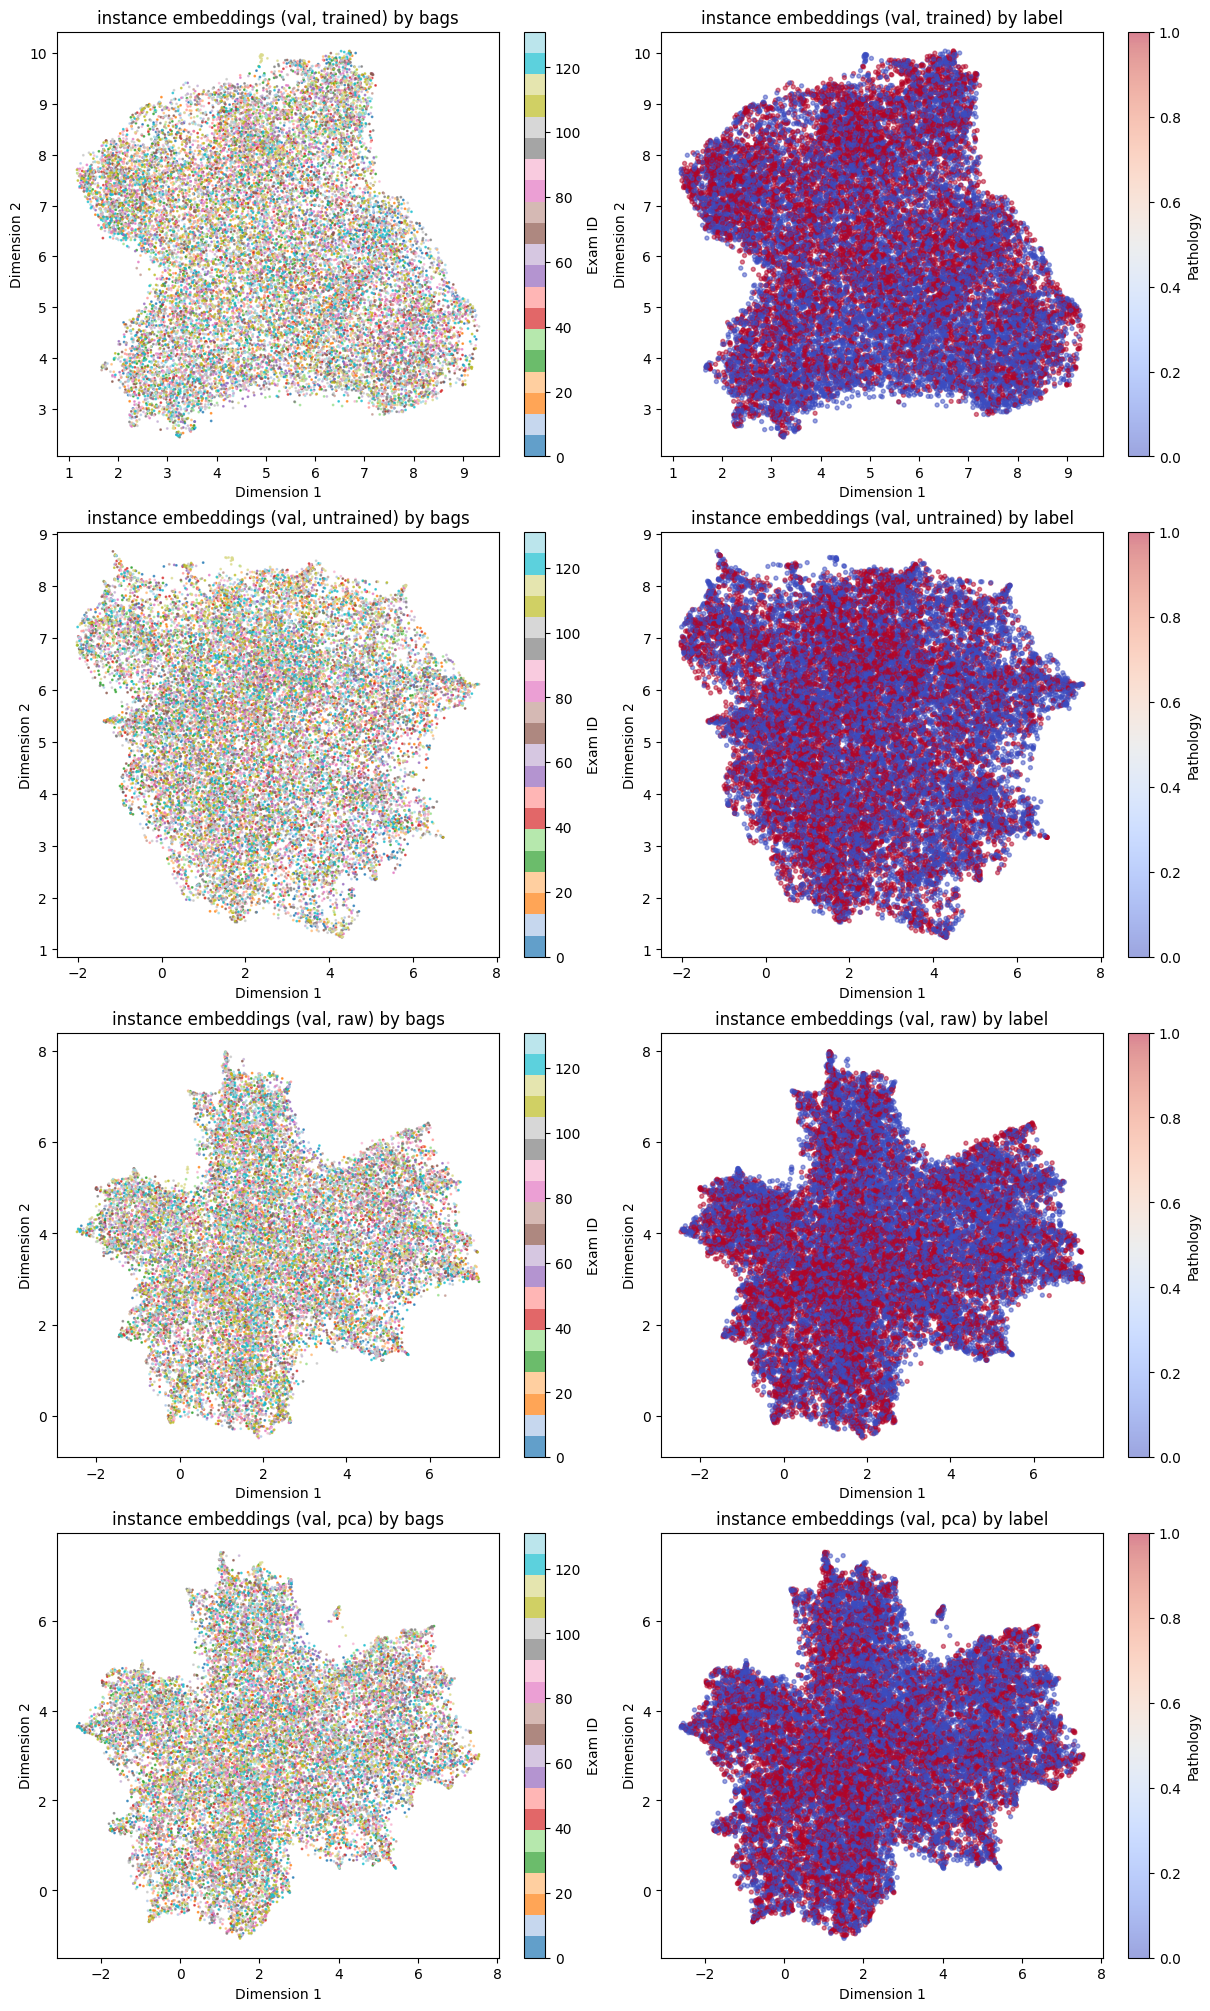

In [14]:
fig, axes = plt.subplots(4, 2, figsize=(12, 20), constrained_layout=True)

for row, (name, embedding) in enumerate(embeddings.items()):

    ax = axes[row, 0]
    scatter = ax.scatter(embedding[:, 0], #type:ignore
                    embedding[:, 1],  #type:ignore
                    c=exam_ids, 
                    cmap="tab20", 
                    s=1, 
                    alpha=0.7, 
                    rasterized=True)
    
    ax.set_title(f"instance embeddings (val, {name}) by bags")
    ax.set_xlabel("Dimension 1")
    ax.set_ylabel("Dimension 2")
    fig.colorbar(scatter, ax=ax, label="Exam ID")


    ax = axes[row, 1]
    scatter = ax.scatter(embedding[:, 0], #type:ignore
                    embedding[:, 1], #type:ignore
                    c=window_labels, 
                    cmap="coolwarm", 
                    s=8, 
                    alpha=0.5, 
                    rasterized=True)
    
    ax.set_title(f"instance embeddings (val, {name}) by label")
    ax.set_xlabel("Dimension 1")
    ax.set_ylabel("Dimension 2")
    fig.colorbar(scatter, ax=ax, label="Pathology")

plt.show()

In [16]:
rows = run_nn_probes(bags, representations, y_train, y_val, y_test,
                     lr=1e-3, 
                     batch_size=100, 
                     max_epochs=200)

[trained_ae] LinearBagProbe  val AUC = 0.668  epoch = 19  test AUC = 0.627
[trained_ae] LinearInstanceProbeBagLabels  val AUC = 0.638  epoch = 2  test AUC = 0.627
[untrained_ae] LinearBagProbe  val AUC = 0.669  epoch = 100  test AUC = 0.654
[untrained_ae] LinearInstanceProbeBagLabels  val AUC = 0.610  epoch = 24  test AUC = 0.603
[pca] LinearBagProbe  val AUC = 0.690  epoch = 33  test AUC = 0.612
[pca] LinearInstanceProbeBagLabels  val AUC = 0.659  epoch = 32  test AUC = 0.602
[raw] LinearBagProbe  val AUC = 0.705  epoch = 4  test AUC = 0.635
[raw] LinearInstanceProbeBagLabels  val AUC = 0.690  epoch = 14  test AUC = 0.629


In [18]:
res_df = pd.DataFrame(rows).set_index(["Representation", "Method"])
res_df
#res_df.to_csv(f"{out_dir}/probe_results/{split_k}.csv", index = False)

Val AUC  Epoch  Test AUC  \
Representation Method                                                    
trained_ae     LinearBagProbe                0.667750     19  0.626756   
               LinearInstanceProbeBagLabels  0.638263      2  0.626756   
untrained_ae   LinearBagProbe                0.669143    100  0.654404   
               LinearInstanceProbeBagLabels  0.609937     24  0.602676   
pca            LinearBagProbe                0.690039     33  0.611594   
               LinearInstanceProbeBagLabels  0.659392     32  0.602007   
raw            LinearBagProbe                0.704899      4  0.635229   
               LinearInstanceProbeBagLabels  0.690272     14  0.629431   

                                             Test bAcc  
Representation Method                                   
trained_ae     LinearBagProbe                 0.602564  
               LinearInstanceProbeBagLabels   0.581382  
untrained_ae   LinearBagProbe                 0.616165  
               LinearInstanceProbeBagLabels   0.549721  
pca            LinearBagProbe                 0.558194  
               LinearInstanceProbeBagLabels   0.545596  
raw            LinearBagProbe                 0.581717  
               LinearInstanceProbeBagLabels   0.575920